In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem1

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
env = problem1.environment(sigma_s = 1, b2 = 1e-3)

In [3]:
problem1.expected_signature_bm(env, order = 3, nsims = 1_000)

Tensor([1.0, [1.0, 0.024108528651934975], [[0.5000000000000017, 0.012710588641884705], [0.01139794001005031, 0.48684900555045874]], [[[0.16666666666666757, 0.003261795032159626], [0.006186998577565418, 0.24656043138212327]], [[0.0026054707162424594, 0.000950681204259463], [0.23933789296407593, -0.0017984268410234678]]]])

In [22]:
np.random.seed(123)
dim = 2
order = 2

F = ta.sig_to_tensor([-0.51388435,  2.49080538,  1.94296026,  0.44181134,  1.32224075,
                      0.0505134 ,  0.73690338, -0.63490434,  0.36729093, -0.3888552 ,
                      0.47250208,  1.54459037, -0.99353251, -0.81156736,  0.47245762], dim, order=3)
strag_sig = problem1.sig_strag_dot(F, order = 7)

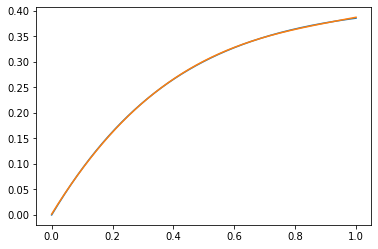

In [23]:
sigma_alpha_hat = env.b1*env.V_alpha/env.sigma_s
p_coef = np.polyfit(env.timesteps, sigma_alpha_hat, deg = 3)
sigma_alpha_hat_fit = np.polyval(p_coef, env.timesteps)
plt.plot(env.timesteps, sigma_alpha_hat)
plt.plot(env.timesteps, sigma_alpha_hat_fit)

In [24]:
p_coef_reversed = p_coef[::-1]

In [25]:
trunc_lev = 3
trunc_lev_1 = 3

f_s = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
for k in range(len(p_coef_reversed)):
    word_tensor = ta.word(word,dim)
    f_s += word_tensor*p_coef_reversed[k]
    word = (0,) + word
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev)
f_s = f_s*exp_a1
f_s = f_s*(ta.word((0,),dim)*env.b1)
f_s += ta.word((1,),dim)*env.sigma_s
f_s += ta.word((0,),dim)*env.b0
f_s += F*(ta.word((0,),dim)*env.b2)
f_s += ta.word((),dim)*env.S0 
f_s = f_s.truncate(trunc_lev)

f_alpha = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
for k in range(len(p_coef_reversed)):
    word_tensor = ta.word(word,dim)
    f_alpha += word_tensor*p_coef_reversed[k]
    word = (0,) + word
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev_1)
f_alpha = f_alpha*exp_a1
f_alpha = f_alpha.truncate(trunc_lev_1)

In [26]:
nsims = 10

env.simulate(nsims, strag_sig)

In [9]:
import optimiser_new

In [10]:
np.random.seed(456)
optimiser_1 = optimiser_new.Optimiser(env)

In [27]:
F_old = np.array([-9.31303061e+03,  1.70470164e+05,  1.76763133e+04,  6.27444060e+03,
                  -1.77715626e+01,  2.67578380e+01,  9.35282912e+03, -1.73338906e+02,
                  -1.90193071e+01, -3.50962197e+01,  1.22302311e+02,  1.52350598e+02,
                  -4.29655035e+01,  5.38159503e+01,  8.68563838e+01])

array([-9.31303061e+03,  1.70470164e+05,  1.76763133e+04,  6.27444060e+03,
       -1.77715626e+01,  2.67578380e+01,  9.35282912e+03, -1.73338906e+02,
       -1.90193071e+01, -3.50962197e+01,  1.22302311e+02,  1.52350598e+02,
       -4.29655035e+01,  5.38159503e+01,  8.68563838e+01])

In [28]:
F_new = F.flatten()

optimiser_1.value_fn(F_new, poly_deg = 3, trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-0.01381642679577704

In [29]:
f_s_sig = problem1.sig_strag_dot(f_s, order = trunc_lev)
f_alpha_sig = problem1.sig_strag_dot(f_alpha, order = trunc_lev_1)

S_sig = np.zeros((env.Nt+1,nsims))
alpha_hat_sig = np.zeros((env.Nt+1,nsims))

for it in range(env.Nt+1):
    S_sig[it,:] = f_s_sig(env,it)
    alpha_hat_sig[it,:] = f_alpha_sig(env,it)
    #S_sig[it,:] = strag_sig(env,it)

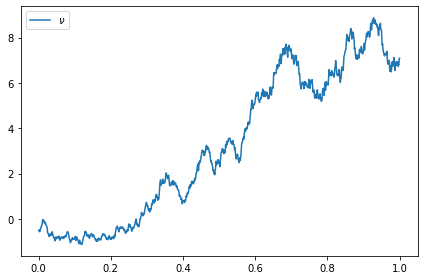

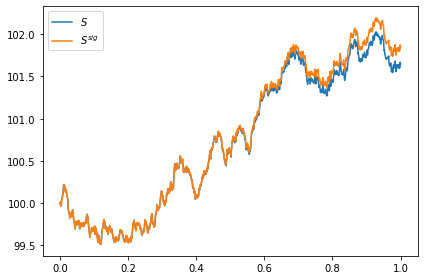

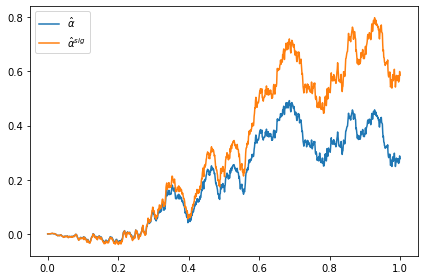

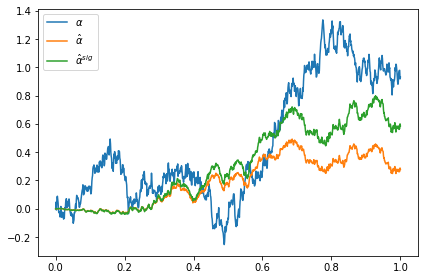

In [33]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
env.X[-1,:] + env.Q[-1,:]*env.S[-1,:]

array([-2.41334184e-01, -1.51535046e-04,  2.67739808e-01, -3.79577397e-01,
       -2.94984834e-01, -2.38377882e+00, -2.57442424e-01,  3.67364783e-01,
        1.17685291e+00,  6.37693842e-01])

In [15]:
optimiser_1.train(poly_deg = 3, trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

Optimising: 4it [23:38, 354.68s/it]

Done in 1418.719383239746 seconds. Maximum value: 0.013816426756760408


In [19]:
optimiser_1.F.flatten()

array([-0.51388435,  2.49080538,  1.94296026,  0.44181134,  1.32224075,
        0.0505134 ,  0.73690338, -0.63490434,  0.36729093, -0.3888552 ,
        0.47250208,  1.54459037, -0.99353251, -0.81156736,  0.47245762])

In [20]:
optimiser_1.value_fn(optimiser_1.F.flatten(), poly_deg = 3, trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-0.013816426756760408

In [21]:
optimiser_1.value_fn(F.flatten(), poly_deg = 3, trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-5947497.053509215